# Яндекс Афиша

- Автор:Айнур Аймурзиева
- Дата:6.10.2026

## Цели и задачи проекта

Провести исследовательский анализ пользовательского поведения в Яндекс Афише.

### Описание данных

Датасет `final_tickets_orders_df.csv` включает информацию обо всех заказах билетов, совершённых с двух типов устройств — мобильных и стационарных:
- `order_id` — уникальный идентификатор заказа.
- `user_id` — уникальный идентификатор пользователя.
- `created_dt_msk` — дата создания заказа (московское время).
- `created_ts_msk` — дата и время создания заказа (московское время).
- `event_id` — идентификатор мероприятия из таблицы events.
- `cinema_circuit` — сеть кинотеатров. Если не применимо, то здесь будет значение 'нет'.
- `age_limit` — возрастное ограничение мероприятия.
- `currency_code` — валюта оплаты, например rub для российских рублей.
- `device_type_canonical` — тип устройства, с которого был оформлен заказ, например mobile для мобильных устройств, desktop для стационарных.
- `revenue` — выручка от заказа.
- `service_name` — название билетного оператора.
- `tickets_count` — количество купленных билетов.
- `total` — общая сумма заказа.
- `days_since_prev` - количество дней с предыдущей покупки для каждого пользователя. Если покупки не было, то данные содержат пропуск.

Датасет `final_tickets_events_df` содержит информацию о событиях, включая город и регион события, а также информацию о площадке проведения мероприятия. Датасет содержит такие поля:
- `event_id` — уникальный идентификатор мероприятия.
- `event_name` — название мероприятия. Аналог поля event_name_code из исходной базы данных.
- `event_type_description` — описание типа мероприятия.
- `event_type_main` — основной тип мероприятия: театральная постановка, концерт и так далее.
- `organizers` — организаторы мероприятия.
- `region_name` — название региона.
- `city_name` — название города.
- `venue_id` — уникальный идентификатор площадки.
- `venue_name` — название площадки.
- `venue_address` — адрес площадки.

Датасет `final_tickets_tenge_df.csv` с информацией о курсе тенге к российскому рублю за 2024 год. Значения в рублях представлено для 100 тенге. Датасет содержит такие поля:
- `nominal` — номинал (100 тенге).
- `data` — дата.
- `curs` — курс тенге к рублю.
- `cdx` — обозначение валюты (kzt).

### Содержимое проекта

1. Загрузка данных и знакомство с ними
2. Предобработка данных
3. Исследовательский анализ данных
4. Статистический анализ данных
5. Общий вывод и рекомендации

---

## 1. Загрузка данных и знакомство с ними

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind, mannwhitneyu

In [2]:
orders_df=pd.read_csv('/datasets/final_tickets_orders_df.csv')
events_df=pd.read_csv('/datasets/final_tickets_events_df.csv')
tenge_df=pd.read_csv('/datasets/final_tickets_tenge_df.csv')

In [3]:
orders_df.head()

,order_id,user_id,created_dt_msk,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,service_name,tickets_count,total,days_since_prev
0,4359165,0002849b70a3ce2,2024-08-20,2024-08-20 16:08:03,169230,нет,16,rub,mobile,1521.94,Край билетов,4,10870.99,NaN
1,7965605,0005ca5e93f2cf4,2024-07-23,2024-07-23 18:36:24,237325,нет,0,rub,mobile,289.45,Мой билет,2,2067.51,NaN
2,7292370,0005ca5e93f2cf4,2024-10-06,2024-10-06 13:56:02,578454,нет,0,rub,mobile,1258.57,За билетом!,4,13984.16,75.0
3,1139875,000898990054619,2024-07-13,2024-07-13 19:40:48,387271,нет,0,rub,mobile,8.49,Лови билет!,2,212.28,NaN
4,972400,000898990054619,2024-10-04,2024-10-04 22:33:15,509453,нет,18,rub,mobile,1390.41,Билеты без проблем,3,10695.43,83.0


In [4]:
orders_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290849 entries, 0 to 290848
Data columns (total 14 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   order_id               290849 non-null  int64  
 1   user_id                290849 non-null  object 
 2   created_dt_msk         290849 non-null  object 
 3   created_ts_msk         290849 non-null  object 
 4   event_id               290849 non-null  int64  
 5   cinema_circuit         290849 non-null  object 
 6   age_limit              290849 non-null  int64  
 7   currency_code          290849 non-null  object 
 8   device_type_canonical  290849 non-null  object 
 9   revenue                290849 non-null  float64
 10  service_name           290849 non-null  object 
 11  tickets_count          290849 non-null  int64  
 12  total                  290849 non-null  float64
 13  days_since_prev        268909 non-null  float64
dtypes: float64(3), int64(4), object(7)
m

### Промежуточный вывод о датафрейме orders_df

    
Датасет `final_tickets_orders_df.csv` содержит 14 столбцов и 290848 строк, в которых представлена информация обо всех заказах билетов.

После первичного анализа данных можно сделать следующие выводы:
- Все представленные данные содержат числовые и строчные значения, хранятся в типах данных `float64`, `int64` или `object`. 
- Столбцы `created_dt_msk` и `created_ts_msk` для дальнейшего анализа нужно поменять на тип даты и времени.
- Пропуски содержатся только в столбце `days_since_prev`. Cледует проверить и решить как работать с пропусками.
- Судя по первому знакомству с данными, значения в столбцах соответствуют своему описанию.

Первичное знакомство показывает, что данные хорошего качества соответствуют описанию и выглядят корректными.

In [5]:
events_df.head()

,event_id,event_name,event_type_description,event_type_main,organizers,region_name,city_name,city_id,venue_id,venue_name,venue_address
0,4436,e4f26fba-da77-4c61-928a-6c3e434d793f,спектакль,театр,№4893,Североярская область,Озёрск,2,1600,"Кладбище искусств ""Проблема"" и партнеры","наб. Загородная, д. 785"
1,5785,5cc08a60-fdea-4186-9bb2-bffc3603fb77,спектакль,театр,№1931,Светополянский округ,Глиноград,54,2196,"Лекции по искусству ""Свет"" Групп","ул. Ягодная, д. 942"
2,8817,8e379a89-3a10-4811-ba06-ec22ebebe989,спектакль,театр,№4896,Североярская область,Озёрск,2,4043,"Кинокомитет ""Золотая"" Инк","ш. Коммуны, д. 92 стр. 6"
3,8849,682e3129-6a32-4952-9d8a-ef7f60d4c247,спектакль,театр,№4960,Каменевский регион,Глиногорск,213,1987,"Выставка ремесел ""Свет"" Лтд","пер. Набережный, д. 35"
4,8850,d6e99176-c77f-4af0-9222-07c571f6c624,спектакль,театр,№4770,Лесодальний край,Родниковец,55,4230,"Фестивальный проект ""Листья"" Групп","пер. Проезжий, д. 9"


In [6]:
events_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22427 entries, 0 to 22426
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   event_id                22427 non-null  int64 
 1   event_name              22427 non-null  object
 2   event_type_description  22427 non-null  object
 3   event_type_main         22427 non-null  object
 4   organizers              22427 non-null  object
 5   region_name             22427 non-null  object
 6   city_name               22427 non-null  object
 7   city_id                 22427 non-null  int64 
 8   venue_id                22427 non-null  int64 
 9   venue_name              22427 non-null  object
 10  venue_address           22427 non-null  object
dtypes: int64(3), object(8)
memory usage: 1.9+ MB


### Промежуточный вывод о датафрейме events_df

    
Датасет `final_tickets_events_df.csv` содержит 11 столбцов и 22426 строк, в которых представлена информация о событиях, включая город и регион события, а также информацию о площадке проведения мероприятия.

После первичного анализа данных можно сделать следующие выводы:
- Все представленные данные содержат числовые и строчные значения, хранятся в типах данных `int64` или `object`. 
- Пропуски отсутсвуют.
- Судя по первому знакомству с данными, значения в столбцах соответствуют своему описанию.

Первичное знакомство показывает, что данные хорошего качества соответствуют описанию и выглядят корректными.

In [7]:
tenge_df.head()

,data,nominal,curs,cdx
0,2024-01-10,100,19.9391,kzt
1,2024-01-11,100,19.7255,kzt
2,2024-01-12,100,19.5839,kzt
3,2024-01-13,100,19.4501,kzt
4,2024-01-14,100,19.4501,kzt


In [8]:
tenge_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 357 entries, 0 to 356
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   data     357 non-null    object 
 1   nominal  357 non-null    int64  
 2   curs     357 non-null    float64
 3   cdx      357 non-null    object 
dtypes: float64(1), int64(1), object(2)
memory usage: 11.3+ KB


### Промежуточный вывод о датафрейме events_df

    
Датасет `final_tickets_tenge_df.csv` содержит 4 столбца и 356 строк, в которых представлена информация о о курсе тенге к российскому рублю за 2024 год.
После первичного анализа данных можно сделать следующие выводы:
- Все представленные данные содержат числовые и строчные значения, хранятся в типах данных `float64`, `int64` или `object`. 
- Пропуски отсутсвуют.
- Судя по первому знакомству с данными, значения в столбцах соответствуют своему описанию.

Первичное знакомство показывает, что данные хорошего качества соответствуют описанию и выглядят корректными.

## 2. Предобработка данных

In [9]:
# Соединяем данные в единый датафрейм df
df = orders_df.merge(events_df, how='left', on='event_id')

In [10]:
# Сохраняем изначальное количество строк до предобработки
initial_row_count = df.shape[0]
initial_row_count

290849

In [11]:
# Подсчитываем строки с пропусками
df.isna().sum()

order_id                      0
user_id                       0
created_dt_msk                0
created_ts_msk                0
event_id                      0
cinema_circuit                0
age_limit                     0
currency_code                 0
device_type_canonical         0
revenue                       0
service_name                  0
tickets_count                 0
total                         0
days_since_prev           21940
event_name                  238
event_type_description      238
event_type_main             238
organizers                  238
region_name                 238
city_name                   238
city_id                     238
venue_id                    238
venue_name                  238
venue_address               238
dtype: int64

In [12]:
# Подсчитываем долю строк с пропусками
df.isna().mean().sort_values()

order_id                  0.000000
total                     0.000000
service_name              0.000000
revenue                   0.000000
device_type_canonical     0.000000
currency_code             0.000000
tickets_count             0.000000
cinema_circuit            0.000000
event_id                  0.000000
created_ts_msk            0.000000
created_dt_msk            0.000000
user_id                   0.000000
age_limit                 0.000000
venue_id                  0.000818
city_id                   0.000818
city_name                 0.000818
region_name               0.000818
event_type_description    0.000818
event_type_main           0.000818
event_name                0.000818
venue_name                0.000818
organizers                0.000818
venue_address             0.000818
days_since_prev           0.075434
dtype: float64

In [13]:
df[df['event_name'].isna()].head()

,order_id,user_id,created_dt_msk,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,...,event_name,event_type_description,event_type_main,organizers,region_name,city_name,city_id,venue_id,venue_name,venue_address
62,6493246,002ec276eee9b0b,2024-10-14,2024-10-14 16:27:53,533222,нет,6,rub,mobile,78.75,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
63,6493275,002ec276eee9b0b,2024-10-14,2024-10-14 16:22:38,533222,нет,6,rub,mobile,78.75,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
64,6493304,002ec276eee9b0b,2024-10-14,2024-10-14 16:29:20,533222,нет,6,rub,mobile,118.12,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
237,8272280,00da083909dc06b,2024-06-07,2024-06-07 17:50:50,530296,нет,18,rub,mobile,0.00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
238,8272512,00da083909dc06b,2024-06-07,2024-06-07 17:49:16,530296,нет,18,rub,mobile,0.00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [14]:
# Анализ категориальных значений
for column in ['age_limit', 'currency_code', 'device_type_canonical', 'service_name']:
    print(f"\nColumn: {column}")
    print("Unique values:", df[column].unique())
    print("Missing values count:", df[column].isna().sum())
    print("Value counts:")
    print(df[column].value_counts(dropna=False), "\n")


Column: age_limit
Unique values: [16  0 18 12  6]
Missing values count: 0
Value counts:
16    78579
12    62557
0     61487
6     52173
18    36053
Name: age_limit, dtype: int64 


Column: currency_code
Unique values: ['rub' 'kzt']
Missing values count: 0
Value counts:
rub    285780
kzt      5069
Name: currency_code, dtype: int64 


Column: device_type_canonical
Unique values: ['mobile' 'desktop']
Missing values count: 0
Value counts:
mobile     232679
desktop     58170
Name: device_type_canonical, dtype: int64 


Column: service_name
Unique values: ['Край билетов' 'Мой билет' 'За билетом!' 'Лови билет!'
 'Билеты без проблем' 'Облачко' 'Лучшие билеты' 'Прачечная' 'Быстробилет'
 'Дом культуры' 'Весь в билетах' 'Билеты в руки' 'Тебе билет!'
 'Show_ticket' 'Городской дом культуры' 'Яблоко' 'Билет по телефону'
 'Выступления.ру' 'Росбилет' 'Шоу начинается!' 'Мир касс' 'Восьмёрка'
 'Телебилет' 'Crazy ticket!' 'Реестр' 'Быстрый кассир' 'КарандашРУ'
 'Радио ticket' 'Дырокол' 'Вперёд!' 'Кино б

In [15]:
rub_revenue=df['revenue'][orders_df['currency_code']=='rub']
# Изучаем статистические показатели столбца revenue:
print('Статистические показатели столбца rub_revenue:')
rub_revenue.describe()

Статистические показатели столбца rub_revenue:


count    285780.000000
mean        547.568333
std         871.524559
min         -90.760000
25%         113.827500
50%         346.100000
75%         791.700000
max       81174.540000
Name: revenue, dtype: float64

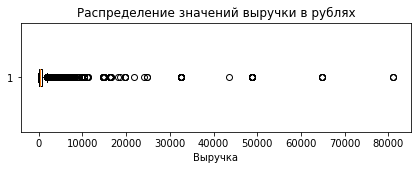

In [16]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(7, 2))

# Строим диаграмму размаха значений в столбце balance
plt.boxplot(rub_revenue, vert=False)

# Добавляем заголовок и метки оси
plt.title('Распределение значений выручки в рублях')
plt.xlabel('Выручка')

# Выводим график
plt.show()

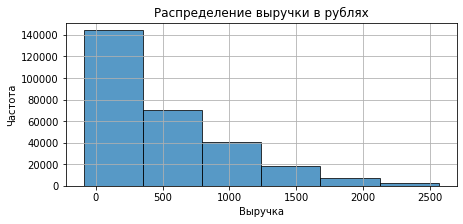

In [17]:
rub_99 = rub_revenue[rub_revenue <= rub_revenue.quantile(0.99)]

plt.figure(figsize=(7, 3))

# Строим гистограмму с помощью pandas через plot(kind='hist')
rub_99.plot(
                kind='hist', # Тип графика - гистограмма
                bins=6, # Устанавливаем количество корзин
                alpha=0.75,
                edgecolor='black',
)

# Настраиваем оформление графика
plt.title('Распределение выручки в рублях')
plt.xlabel('Выручка')
plt.ylabel('Частота')
# Добавляем сетку графика
plt.grid()

# Выводим график
plt.show()

In [18]:
kzt_revenue=df['revenue'][df['currency_code']=='kzt']
# Изучаем статистические показатели столбца revenue:
print('Статистические показатели столбца rub_revenue:')
kzt_revenue.describe()

Статистические показатели столбца rub_revenue:


count     5069.000000
mean      4995.206767
std       4916.752776
min          0.000000
25%        518.100000
50%       3698.830000
75%       7397.660000
max      26425.860000
Name: revenue, dtype: float64

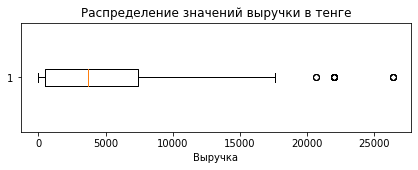

In [19]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(7, 2))

# Строим диаграмму размаха значений в столбце balance
plt.boxplot(kzt_revenue, vert=False)

# Добавляем заголовок и метки оси
plt.title('Распределение значений выручки в тенге')
plt.xlabel('Выручка')

# Выводим график
plt.show()

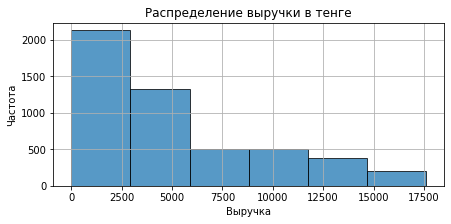

In [20]:
kzt_99 = kzt_revenue[kzt_revenue <= kzt_revenue.quantile(0.99)]

plt.figure(figsize=(7, 3))

# Строим гистограмму с помощью pandas через plot(kind='hist')
kzt_99.plot(
                kind='hist', # Тип графика - гистограмма
                bins=6, # Устанавливаем количество корзин
                alpha=0.75,
                edgecolor='black',
)

# Настраиваем оформление графика
plt.title('Распределение выручки в тенге')
plt.xlabel('Выручка')
plt.ylabel('Частота')
# Добавляем сетку графика
plt.grid()

# Выводим график
plt.show()

In [21]:
# Оставляем строки до 99-го процентиля внутри каждой валюты
df = df[((df['currency_code'] == 'rub') & (df['revenue'] <= df.loc[df['currency_code'] == 'rub', 'revenue'].quantile(0.99))) |
        ((df['currency_code'] == 'kzt') & (df['revenue'] <= df.loc[df['currency_code'] == 'kzt', 'revenue'].quantile(0.99)))]

In [22]:
# Изучаем статистические показатели столбца tickets_count:
print('Статистические показатели столбца tickets_count:')
df['tickets_count'].describe()

Статистические показатели столбца tickets_count:


count    287962.000000
mean          2.739889
std           1.162301
min           1.000000
25%           2.000000
50%           3.000000
75%           3.000000
max          57.000000
Name: tickets_count, dtype: float64

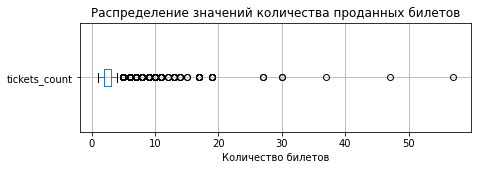

In [23]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(7, 2))

# Строим диаграмму размаха значений в столбце balance
df.boxplot(column='tickets_count', vert=False)

# Добавляем заголовок и метки оси
plt.title('Распределение значений количества проданных билетов')
plt.xlabel('Количество билетов')

# Выводим график
plt.show()

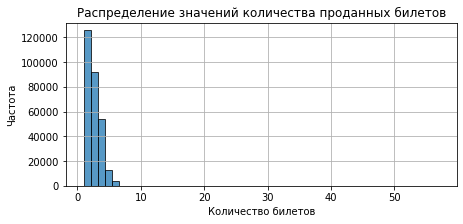

In [24]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(7, 3))

# Строим гистограмму с помощью pandas через plot(kind='hist')
df['tickets_count'].plot(
                kind='hist', # Тип графика - гистограмма
                bins=50, # Устанавливаем количество корзин
                alpha=0.75,
                edgecolor='black',
                rot=0, # Градус вращения подписи по оси Х
)

# Настраиваем оформление графика
plt.title('Распределение значений количества проданных билетов')
plt.xlabel('Количество билетов')
plt.ylabel('Частота')
# Добавляем сетку графика
plt.grid()

# Выводим график
plt.show()

In [25]:
# Проверяем явные и неявные дубликаты orders_df
df.duplicated().sum()

0

In [26]:
# Проверяем неявные дубликаты в датафрейме orders_df
df.duplicated(subset=['user_id', 'event_id', 'created_dt_msk','created_ts_msk','age_limit', 'tickets_count','total','revenue', 'service_name', 'currency_code',
                             'cinema_circuit','device_type_canonical', 'days_since_prev', 'event_type_main', 'city_name']).sum()

30

In [27]:
duplicates = df[df.duplicated(subset=['user_id', 'event_id', 'created_dt_msk','created_ts_msk','age_limit', 'tickets_count','total','revenue', 'service_name', 'currency_code',
                             'cinema_circuit','device_type_canonical', 'days_since_prev'],keep=False)]

duplicates.sort_values('user_id').head()

,order_id,user_id,created_dt_msk,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,...,event_name,event_type_description,event_type_main,organizers,region_name,city_name,city_id,venue_id,venue_name,venue_address
11777,1123983,06eb7897f65b433,2024-08-13,2024-08-13 16:31:07,183706,нет,18,rub,mobile,69.82,...,69796237-909b-42a7-bfb5-c1b8574c4c76,спектакль,театр,№1482,Светополянский округ,Глиноград,54.0,4443.0,"Центр культурного наследия ""Объединение"" и пар...","бул. Карбышева, д. 50"
11778,1123867,06eb7897f65b433,2024-08-13,2024-08-13 16:31:07,183706,нет,18,rub,mobile,69.82,...,69796237-909b-42a7-bfb5-c1b8574c4c76,спектакль,театр,№1482,Светополянский округ,Глиноград,54.0,4443.0,"Центр культурного наследия ""Объединение"" и пар...","бул. Карбышева, д. 50"
57217,160922,2564e3703075008,2024-10-30,2024-10-30 10:04:15,589005,нет,6,rub,mobile,11.23,...,bee8d0cc-282b-492e-9ed8-ec0990f43ffd,выставка,другое,№1810,Яблоневская область,Горяново,11036.0,1656.0,"Модная академия ""Пункт"" Лимитед","бул. Гагарина, д. 39"
57220,160893,2564e3703075008,2024-10-30,2024-10-30 10:04:15,589005,нет,6,rub,mobile,11.23,...,bee8d0cc-282b-492e-9ed8-ec0990f43ffd,выставка,другое,№1810,Яблоневская область,Горяново,11036.0,1656.0,"Модная академия ""Пункт"" Лимитед","бул. Гагарина, д. 39"
84010,3363711,3ee7dc2e115847f,2024-06-25,2024-06-25 07:32:08,277504,нет,6,rub,mobile,59.19,...,dcb6fe75-8502-480d-b8a2-6bee187cb7ee,событие,выставки,№5015,Нежинская область,Каменёвка,76.0,3094.0,"Сообщество художников ""Палитра"" и партнеры","пр. Театральный, д. 161 стр. 2"


In [28]:
df = df.drop_duplicates(subset=['user_id', 'event_id', 'created_dt_msk','created_ts_msk','age_limit', 'tickets_count','total','revenue', 'service_name', 'currency_code',
                             'cinema_circuit','device_type_canonical', 'days_since_prev'])

In [29]:
df.duplicated(subset=['user_id', 'event_id', 'created_dt_msk','created_ts_msk','age_limit', 'tickets_count','total','revenue', 'service_name', 'currency_code',
                             'cinema_circuit','device_type_canonical', 'days_since_prev']).sum()

0

In [30]:
# Проведите преобразования типов данных

In [31]:
# Оптимизируем целочисленный тип данных в датафрейме orders_df
for column in ['age_limit','tickets_count']:
    df[column] = pd.to_numeric(df[column],
                                    downcast='integer')

In [32]:
df['created_dt_msk'] = df['created_dt_msk'].astype('datetime64[ns]')
df['created_ts_msk'] = df['created_ts_msk'].astype('datetime64[ns]')

In [33]:
df.dtypes

order_id                           int64
user_id                           object
created_dt_msk            datetime64[ns]
created_ts_msk            datetime64[ns]
event_id                           int64
cinema_circuit                    object
age_limit                           int8
currency_code                     object
device_type_canonical             object
revenue                          float64
service_name                      object
tickets_count                       int8
total                            float64
days_since_prev                  float64
event_name                        object
event_type_description            object
event_type_main                   object
organizers                        object
region_name                       object
city_name                         object
city_id                          float64
venue_id                         float64
venue_name                        object
venue_address                     object
dtype: object

In [34]:
# Создаем новые столбцов

In [35]:
tenge_df['data'] = tenge_df['data'].astype('datetime64[ns]')
tenge_df.dtypes

data       datetime64[ns]
nominal             int64
curs              float64
cdx                object
dtype: object

In [36]:
df = df.merge(tenge_df,left_on='created_dt_msk',right_on='data',how='left')
df.head()

,order_id,user_id,created_dt_msk,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,...,region_name,city_name,city_id,venue_id,venue_name,venue_address,data,nominal,curs,cdx
0,4359165,0002849b70a3ce2,2024-08-20,2024-08-20 16:08:03,169230,нет,16,rub,mobile,1521.94,...,Каменевский регион,Глиногорск,213.0,3972.0,"Сценический центр ""Деталь"" Групп","алл. Машиностроителей, д. 19 стр. 6",2024-08-20,100,18.6972,kzt
1,7965605,0005ca5e93f2cf4,2024-07-23,2024-07-23 18:36:24,237325,нет,0,rub,mobile,289.45,...,Каменевский регион,Глиногорск,213.0,2941.0,"Музыкальная школа для детей ""Аккаунт"" Лтд","алл. Шмидта, д. 9 стр. 4",2024-07-23,100,18.3419,kzt
2,7292370,0005ca5e93f2cf4,2024-10-06,2024-10-06 13:56:02,578454,нет,0,rub,mobile,1258.57,...,Каменевский регион,Глиногорск,213.0,4507.0,"Училище искусств ""Нирвана"" Инк","алл. Юбилейная, д. 5/6",2024-10-06,100,19.6475,kzt
3,1139875,000898990054619,2024-07-13,2024-07-13 19:40:48,387271,нет,0,rub,mobile,8.49,...,Североярская область,Озёрск,2.0,3574.0,"Театр альтернативного искусства ""Ода"" Лимитед","алл. Есенина, д. 243 к. 3/8",2024-07-13,100,18.5010,kzt
4,972400,000898990054619,2024-10-04,2024-10-04 22:33:15,509453,нет,18,rub,mobile,1390.41,...,Озернинский край,Родниковецк,240.0,1896.0,"Театр кукол ""Огни"" Инкорпорэйтед","ш. Набережное, д. 595 стр. 8",2024-10-04,100,19.6648,kzt


In [37]:
def kzt_rub(x):
    if x['currency_code']=='kzt':
        return (x['revenue']*x['curs'])/x['nominal']
    else:
        return x['revenue']

In [38]:
df['revenue_rub']=df.apply(kzt_rub, axis=1)
df[df['currency_code']=='kzt'].head()

,order_id,user_id,created_dt_msk,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,...,city_name,city_id,venue_id,venue_name,venue_address,data,nominal,curs,cdx,revenue_rub
73,7850214,0033403583a55ed,2024-09-17,2024-09-17 16:52:06,559919,нет,6,kzt,mobile,518.10,...,Серебрянка,163.0,1533.0,"Клуб настольного тенниса ""Фазенда"" Инк","пер. Семашко, д. 8/7 стр. 7",2024-09-17,100,19.0125,kzt,98.503762
91,8634925,0040e12d70fae81,2024-09-02,2024-09-02 19:49:14,559476,нет,6,kzt,desktop,347.18,...,Серебрянка,163.0,1533.0,"Клуб настольного тенниса ""Фазенда"" Инк","пер. Семашко, д. 8/7 стр. 7",2024-09-02,100,18.9330,kzt,65.731589
98,7625522,0054b38b2653e6e,2024-09-09,2024-09-09 18:06:04,559582,нет,6,kzt,mobile,328.77,...,Серебрянка,163.0,1533.0,"Клуб настольного тенниса ""Фазенда"" Инк","пер. Семашко, д. 8/7 стр. 7",2024-09-09,100,18.5991,kzt,61.148261
465,5227657,01370a0e9c1a7d5,2024-06-04,2024-06-04 13:28:17,533803,нет,16,kzt,desktop,7397.66,...,Широковка,162.0,3407.0,"Арт-кафе ""Речка"" Лимитед","алл. Путейская, д. 548 стр. 7",2024-06-04,100,19.9833,kzt,1478.296591
466,2229782,01370a0e9c1a7d5,2024-06-04,2024-06-04 13:17:35,533803,нет,16,kzt,mobile,3698.83,...,Широковка,162.0,3407.0,"Арт-кафе ""Речка"" Лимитед","алл. Путейская, д. 548 стр. 7",2024-06-04,100,19.9833,kzt,739.148295


In [39]:
def ticket_rev(x):
    return x['revenue_rub']/x['tickets_count']

In [40]:
df['one_ticket_revenue_rub']=df.apply(ticket_rev,axis=1)

In [41]:
def month(x):
    return x['created_dt_msk'].month

df['month']=df.apply(month,axis=1)

In [42]:
def seas(x):
    month=x['created_dt_msk'].month
    
    if month in [9, 10, 11]:
        return 'осень'
    elif month in [12, 1, 2]:
        return 'зима'
    elif month in [3, 4, 5]:
        return 'весна'
    else:
        return 'лето'

In [43]:
df['season']=df.apply(seas,axis=1)

In [44]:
df.head()

,order_id,user_id,created_dt_msk,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,...,venue_name,venue_address,data,nominal,curs,cdx,revenue_rub,one_ticket_revenue_rub,month,season
0,4359165,0002849b70a3ce2,2024-08-20,2024-08-20 16:08:03,169230,нет,16,rub,mobile,1521.94,...,"Сценический центр ""Деталь"" Групп","алл. Машиностроителей, д. 19 стр. 6",2024-08-20,100,18.6972,kzt,1521.94,380.4850,8,лето
1,7965605,0005ca5e93f2cf4,2024-07-23,2024-07-23 18:36:24,237325,нет,0,rub,mobile,289.45,...,"Музыкальная школа для детей ""Аккаунт"" Лтд","алл. Шмидта, д. 9 стр. 4",2024-07-23,100,18.3419,kzt,289.45,144.7250,7,лето
2,7292370,0005ca5e93f2cf4,2024-10-06,2024-10-06 13:56:02,578454,нет,0,rub,mobile,1258.57,...,"Училище искусств ""Нирвана"" Инк","алл. Юбилейная, д. 5/6",2024-10-06,100,19.6475,kzt,1258.57,314.6425,10,осень
3,1139875,000898990054619,2024-07-13,2024-07-13 19:40:48,387271,нет,0,rub,mobile,8.49,...,"Театр альтернативного искусства ""Ода"" Лимитед","алл. Есенина, д. 243 к. 3/8",2024-07-13,100,18.5010,kzt,8.49,4.2450,7,лето
4,972400,000898990054619,2024-10-04,2024-10-04 22:33:15,509453,нет,18,rub,mobile,1390.41,...,"Театр кукол ""Огни"" Инкорпорэйтед","ш. Набережное, д. 595 стр. 8",2024-10-04,100,19.6648,kzt,1390.41,463.4700,10,осень


### Промежуточный вывод

- В ходе предобработки пропуски были обнаружены в столбце `days_since_prev`, около 7,5% значений. Их было решено оставить, поскольку для части заказов отсутствует информация о предыдущей покупке пользователя.

- В 238 записях отсутствовала информация о мероприятии. При этом информация о самом заказе и выручке присутствовала, поэтому эти записи были оставлены в датафрейме. Вероятно, информация о соответствующих мероприятиях отсутствовала в исходных данных.

- Распределение выручки в рублях характеризуется значительным разбросом и наличием выбросов. Для дальнейшего анализа были исключены значения выше 99-го процентиля. Аналогичная обработка была проведена для выручки в тенге. 
    
- Столбец `tickets_count` имеет правостороннюю асимметрию и содержит отдельные высокие значения, однако они не исключались.

- Явных дубликатов в датафрейме обнаружено не было.

- При проверке неявных дубликатов без учёта `order_id` было выявлено 30 дубликатов и были удалены.

- Анализ уникальных значений категориальных переменных не выявил очевидных различий в написании категорий, поэтому дополнительная нормализация категориальных данных не потребовалась.

- Столбцы `created_dt_msk` и `created_ts_msk` были преобразованы в формат datetime.

- Для столбцов `age_limit` и `tickets_count` были оптимизированы типы данных.

- В процессе подготовки данных были созданы новые столбцы `revenue_rub`, `month`, `season` и `one_ticket_revenue_rub`.

## 3. Исследовательский анализ данных

### Анализ распределения заказов по сегментам и их сезонные изменения

In [45]:
#Количество заказов для каждого месяца
monthly_orders=df.groupby('month')['order_id'].nunique()
monthly_share=monthly_orders/monthly_orders.sum()
monthly_share

month
6     0.119275
7     0.140346
8     0.154800
9     0.240796
10    0.344783
Name: order_id, dtype: float64

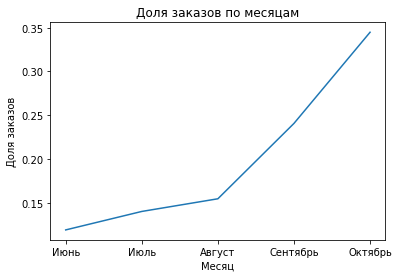

In [46]:
# Строим линейный график
monthly_share.plot.line()

plt.xticks([6, 7, 8, 9, 10],['Июнь', 'Июль', 'Август', 'Сентябрь', 'Октябрь'])

# Настраиваем оси и отображаем график
plt.title('Доля заказов по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Доля заказов')
plt.show()

In [47]:
# Проверяем распределение данных по типу мероприятия
event_type = df.groupby(['season'])['event_type_main'].value_counts(normalize=True).unstack()
event_type

event_type_main,выставки,другое,концерты,спорт,стендап,театр,ёлки
season,,,,,,,
лето,0.020284,0.271759,0.426139,0.025237,0.053279,0.201009,0.002292
осень,0.014450,0.197082,0.371884,0.111997,0.041065,0.253492,0.010031


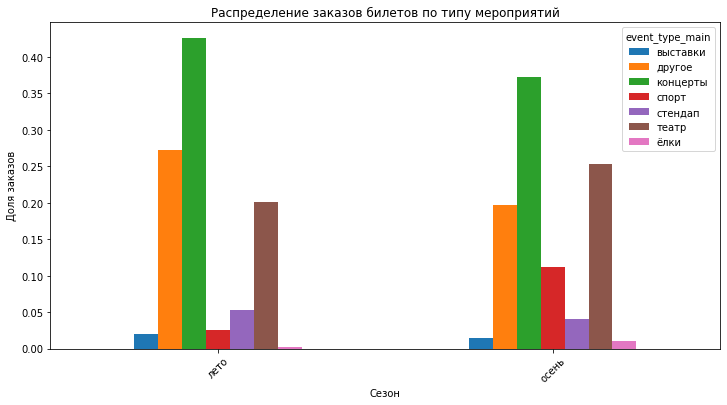

In [48]:
event_type.plot(kind='bar',
               title=f'Распределение заказов билетов по типу мероприятий',
               legend=True,
               ylabel='Доля заказов',
               xlabel='Сезон',
               rot=45,
               figsize=(12, 6))

# Выводим график
plt.show()

In [49]:
# Проверяем распределение данных по типу устройств
device_type = df.groupby(['season'])['device_type_canonical'].value_counts(normalize=True).unstack()
device_type

device_type_canonical,desktop,mobile
season,,
лето,0.193614,0.806386
осень,0.203449,0.796551


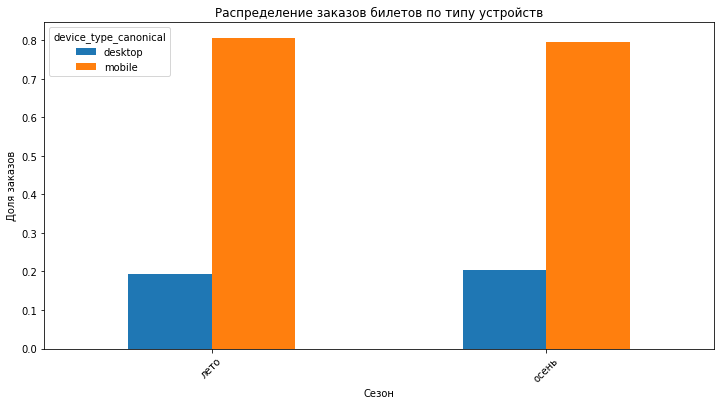

In [50]:
device_type.plot(kind='bar',
               title=f'Распределение заказов билетов по типу устройств',
               legend=True,
               ylabel='Доля заказов',
               xlabel='Сезон',
               rot=45,
               figsize=(12, 6))

# Выводим график
plt.show()

In [51]:
# Проверяем распределение данных по возрастному рейтингу
age_group = df.groupby(['season'])['age_limit'].value_counts(normalize=True).unstack()
age_group

age_limit,0,6,12,16,18
season,,,,,
лето,0.179376,0.181680,0.205489,0.283076,0.150379
осень,0.236218,0.176298,0.220827,0.262255,0.104403


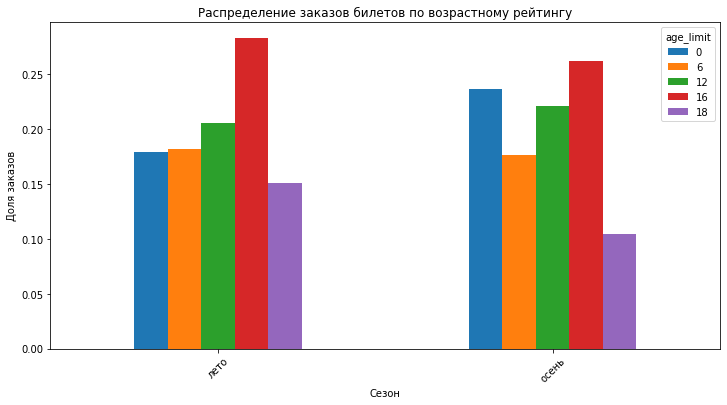

In [52]:
age_group.plot(kind='bar',
               title=f'Распределение заказов билетов по возрастному рейтингу',
               legend=True,
               ylabel='Доля заказов',
               xlabel='Сезон',
               rot=45,
               figsize=(12, 6))

# Выводим график
plt.show()

In [53]:
# Проверяем распределение данных по выручке
rev_season = df.groupby(['season', 'event_type_main'])['one_ticket_revenue_rub'].mean().unstack()
rev_season

event_type_main,выставки,другое,концерты,спорт,стендап,театр,ёлки
season,,,,,,,
лето,86.416198,77.433968,304.717078,50.761831,218.518107,214.126333,271.436176
осень,90.603610,76.115334,268.084074,49.969733,231.124973,175.969508,229.585589


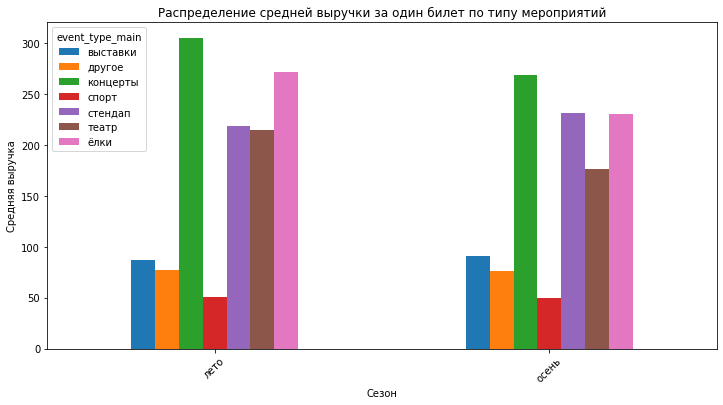

In [54]:
rev_season.plot(kind='bar',
               title=f'Распределение средней выручки за один билет по типу мероприятий',
               legend=True,
               ylabel='Средняя выручка',
               xlabel='Сезон',
               rot=45,
               figsize=(12, 6))

# Выводим график
plt.show()

In [55]:
# Oтносительное изменение осенних значений по сравнению с летними
rev_change = 100*(rev_season.loc['осень']-rev_season.loc['лето'])/rev_season.loc['лето']
rev_change

event_type_main
выставки     4.845634
другое      -1.702914
концерты   -12.021973
спорт       -1.560421
стендап      5.769255
театр      -17.819772
ёлки       -15.418205
dtype: float64

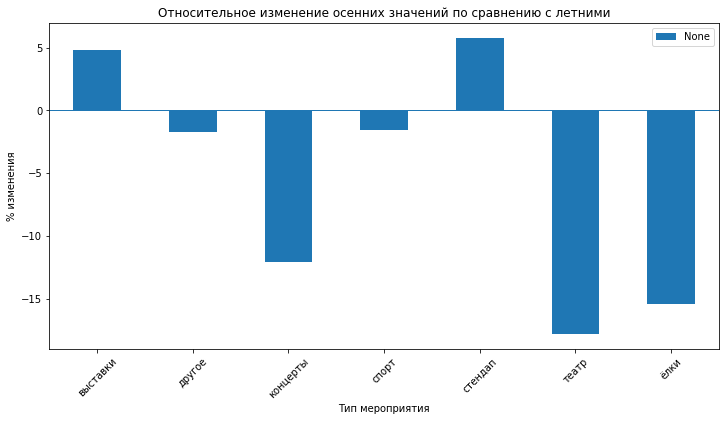

In [56]:
rev_change.plot(kind='bar',
               title=f'Oтносительное изменение осенних значений по сравнению с летними',
               legend=True,
               ylabel='% изменения',
               xlabel='Тип мероприятия',
               rot=45,
               figsize=(12, 6))

plt.axhline(0, linewidth=1)

# Выводим график
plt.show()

- По месяцам наблюдается увеличение количества заказов с конца лета, с наиболее заметным ростом после августа.

- В разрезе типов мероприятий распределение заказов летом и осенью в целом сохраняет схожую структуру. При этом осенью увеличивается доля заказов на спортивные и театральные мероприятия, тогда как доля концертов и категории другое снижается.

- В разрезе устройств структура заказов остаётся примерно одинаковой.

- В разрезе возрастных категорий наиболее часто заказываются мероприятия с возрастным ограничением 16+ как летом, так и осенью. При этом осенью увеличивается доля заказов на мероприятия категории 0+.

- Сравнение средней выручки за один билет показало, что осенью относительно лета выручка увеличилась для выставок и стендапов, тогда как для остальных типов мероприятий наблюдается снижение средней выручки за билет.
    
 

###  Осенняя активность пользователей

In [57]:
autumn=df[df['season']=='осень']

In [58]:
table=autumn.groupby('created_dt_msk').agg(total_order = ('order_id','nunique'),
                                       DAU = ('user_id', 'nunique'),
                                          avg_price = ('one_ticket_revenue_rub', 'mean'))
table['avg_order']=table['total_order']/table['DAU']

<Figure size 432x720 with 0 Axes>

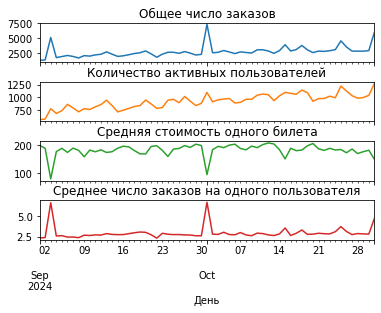

In [59]:
plt.figure(figsize=(6, 10))

# Строим график
table.plot(kind='line',
            subplots=True,
            sharex=True,
            sharey=False,
            legend=False,
            title=['Общее число заказов', 'Количество активных пользователей', 'Средняя стоимость одного билета', 'Среднее число заказов на одного пользователя'])

# Подписываем оси
plt.xlabel('День')
plt.subplots_adjust(hspace=0.5)
plt.show()

In [60]:
week_table=autumn.groupby(autumn['created_dt_msk'].dt.day_name()).agg(total_order = ('order_id','nunique'),
                                       DAU = ('user_id', 'nunique'),
                                          avg_price = ('one_ticket_revenue_rub', 'mean'))
week_table['avg_order']=week_table['total_order']/week_table['DAU']

order = ['Monday', 'Tuesday', 'Wednesday','Thursday', 'Friday', 'Saturday', 'Sunday']

week_table = week_table.reindex(order)
week_table

,total_order,DAU,avg_price,avg_order
created_dt_msk,,,,
Monday,21517,4448,184.081657,4.837455
Tuesday,31480,4793,140.496802,6.567912
Wednesday,22888,4813,185.685146,4.755454
Thursday,27169,4970,177.888277,5.466600
Friday,24828,4870,185.542069,5.098152
Saturday,21336,4571,192.079949,4.667688
Sunday,19389,4394,197.921015,4.412608


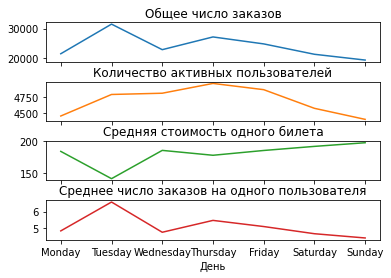

In [61]:
# Строим график
week_table.plot(kind='line',
            subplots=True,
            sharex=True,
            sharey=False,
            legend=False,
            title=['Общее число заказов', 'Количество активных пользователей', 'Средняя стоимость одного билета', 'Среднее число заказов на одного пользователя'])

# Подписываем оси
plt.xlabel('День')
plt.subplots_adjust(hspace=0.5)
plt.show()

    
- В течение осеннего периода пик активности по количеству заказов приходится на 30 сентября. При этом в этот день средняя стоимость одного билета была минимальной.

- Количество активных пользователей постепенно увеличивается с сентября по октябрь, что может свидетельствовать о росте активности аудитории в течение осеннего периода.

- При анализе недельной активности видно, что в выходные дни общее количество заказов и активных пользователей ниже, чем в будние дни. При этом средняя стоимость одного билета постепенно увеличивается к концу рабочей недели и остаётся выше в выходные дни.
 

###  Популярные события и партнёры

После того как изучите изменение популярности событий и пользовательской активности осенью 2024 года, посмотрите, как события распределены по регионам и партнёрам. Это позволит выделить ключевые регионы и партнёров, которые вносят наибольший вклад в выручку.

Для каждого региона посчитайте уникальное количество мероприятий и общее число заказов. В каких регионах предлагается наибольшее разнообразие мероприятий?

Для каждого билетного партнёра посчитайте общее число уникальных мероприятий, обработанных заказов и суммарную выручку с заказов билетов. Сделайте акцент на наиболее активных партнёрах.

Рекомендация: исследуйте не только абсолютные значения, но и доли. Например, для каждого региона посчитайте долю проводимых мероприятий от их общего числа или долю заказов в регионе от общего числа заказов.

В конце напишите промежуточный вывод, проанализируйте не только топ-категории, но и общее распределение данных между категориями. Существуют ли явные лидеры среди регионов и партнёров?

In [62]:
region_group = autumn.groupby('region_name').agg(total_event=('event_id', 'nunique'),
                                                    total_order = ('order_id', 'nunique'))
region_group['event_share']=region_group['total_event']/region_group['total_event'].sum()
region_group['order_share']=region_group['total_order']/region_group['total_order'].sum()

region_sorted=region_group.sort_values('total_event', ascending = False).head(7)

region_sorted

,total_event,total_order,event_share,order_share
region_name,,,,
Каменевский регион,3910,46684,0.246284,0.276917
Североярская область,2613,20718,0.164588,0.122893
Широковская область,803,8715,0.050579,0.051695
Светополянский округ,764,4779,0.048123,0.028348
Речиновская область,529,3565,0.033321,0.021147
Серебринская область,456,4467,0.028723,0.026497
Яблоневская область,432,4199,0.027211,0.024907


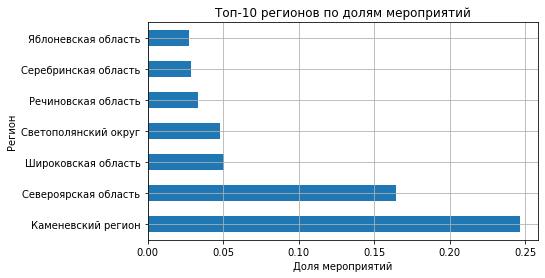

In [63]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(7, 4))

# Строим столбчатую диаграмму с помощью pandas через plot(kind='bar')
region_sorted['event_share'].plot(
               kind='barh', # Тип графика - столбчатая диаграмма
               rot=0, # Градус вращения подписи по оси Х
               legend=False, # Выключаем легенду
               title=f'Топ-10 регионов по долям мероприятий'
)

# Настраиваем оформление графика
plt.ylabel('Регион')
plt.xlabel('Доля мероприятий')
# Добавляем сетку графика
plt.grid()

# Выводим график
plt.show()

In [64]:
partner_group = autumn.groupby('service_name').agg(total_event=('event_id', 'nunique'),
                                                    total_order = ('order_id', 'nunique'),
                                               total_revenue = ('revenue_rub', 'sum'))
partner_group['event_share']=partner_group['total_event']/partner_group['total_event'].sum()
partner_group['order_share']=partner_group['total_order']/partner_group['total_order'].sum()
partner_group['revenue_share']=partner_group['total_revenue']/partner_group['total_revenue'].sum()

partner_sorted=partner_group.sort_values('total_revenue', ascending = False).head(7)

partner_sorted

,total_event,total_order,total_revenue,event_share,order_share,revenue_share
service_name,,,,,,
Билеты без проблем,2847,32383,1.211601e+07,0.164547,0.192062,0.148165
Мой билет,1006,19419,1.085081e+07,0.058144,0.115173,0.132693
Облачко,1409,15478,1.061105e+07,0.081436,0.091799,0.129761
Лови билет!,3616,25792,1.037679e+07,0.208993,0.152971,0.126896
Весь в билетах,599,9406,9.325571e+06,0.034620,0.055787,0.114041
Билеты в руки,2471,25734,7.613966e+06,0.142816,0.152627,0.093110
Край билетов,193,2997,3.018373e+06,0.011155,0.017775,0.036911


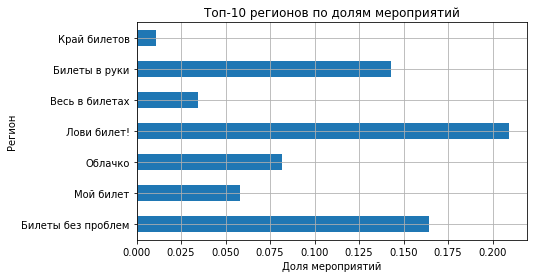

In [65]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(7, 4))

# Строим столбчатую диаграмму с помощью pandas через plot(kind='bar')
partner_sorted['event_share'].plot(
               kind='barh', # Тип графика - столбчатая диаграмма
               rot=0, # Градус вращения подписи по оси Х
               legend=False, # Выключаем легенду
               title=f'Топ-10 регионов по долям мероприятий'
)

# Настраиваем оформление графика
plt.ylabel('Регион')
plt.xlabel('Доля мероприятий')
# Добавляем сетку графика
plt.grid()

# Выводим график
plt.show()

    
- Каменевский регион занимает первое место, на него приходится 24.8% всех мероприятий и 27.9% всех заказов. Второе место занимает Североярская область, 16.5% мероприятий и 12.3% заказов. Широковская область занимает третье место по разнообразию мероприятий с долей 5.0% и также входит в число лидеров по количеству заказов.

- В нижней части распределения встречаются регионы всего с несколькими уникальными мероприятиями. Это указывает на высокую концентрацию предложения мероприятий в отдельных регионах.

- Среди партнёров 'Лови билет!' обработал 15.2% всех заказов, при этом его доля уникальных мероприятий составляет 20.8% и выручка 12.6%. Партнёр 'Билеты без проблем' имеет более высокую выручку, около 14.8%, а доля заказов состовляет 19.2%. Это показывает, что количество мероприятий не всегда напрямую связано с количеством заказов и объёмом выручки.

## Статистический анализ данных

In [66]:
order_per_user=autumn.groupby(['device_type_canonical', 'user_id'])['order_id'].nunique().reset_index(name='order_per_user')

In [67]:
metric_a = order_per_user[order_per_user['device_type_canonical'] == 'mobile']['user_id']
metric_b = order_per_user[order_per_user['device_type_canonical'] == 'desktop']['user_id']

intersection = list(set(metric_a) & set(metric_b))
print(intersection)

['1e2afac1d708d5d', '53534608a75bbe4', '7067c82ba14a04d', 'f60b9fb57caf00f', '0ce2ad8e57593f5', '4e031d3f119c8fd', '59d7d5fb6eb4964', 'd5f07a65694f995', 'c1e312ca0970f0e', '71b552cf47efb10', '3d44eab7c14d03b', '46ad6fc83280a13', 'c1491e5f15edfba', 'b6d359e7e53f88b', 'dac78d4d20174b9', 'b5c27fea91cd0ee', '47eab9096524504', '533151275d676d0', 'd63a4755fe92a14', '7f9f91757ca4433', 'a0258a2fb4a1bb0', '284d5a2eb482574', 'aa0f956fba541b4', '8d60ded48987df8', 'db6d40d98e73a5d', 'cf162d60a3a476a', '400a9250378dab2', 'd1e72c97b9d86b3', '028fcb4f94d2565', '252a07c65c85971', '97344ba9e3ec2d5', '4317190198f3544', '50b153c891c7c45', '1c191bb7b007ba1', '98625276fe1f626', 'd73b32e58cee9af', 'a79dcc999e1cb84', 'e91ee82a4afe4c8', 'c514c06c63aef08', 'c1c7641fd348ed1', '3ba782cd0a08cf5', '0fcbe6520a0589f', '206ea45ec11d478', '5dc91cc267d9dc4', '555f21eb8353de4', '0f3885761f45ad4', 'fd4d47438ebb946', '5619806b384f7c3', '6f9b4e4421b1886', '19654a28676ff03', '96c0751d65520e0', '4678b687aef94db', '0da8138bbc

In [68]:
order_per_user = order_per_user[~order_per_user['user_id'].isin(intersection)] 

In [69]:
avg_order=order_per_user.groupby('device_type_canonical')['order_per_user'].mean()
avg_order

device_type_canonical
desktop    1.974676
mobile     2.858501
Name: order_per_user, dtype: float64

In [70]:
diff = avg_order['mobile']-avg_order['desktop']
diff

0.8838251883201427

Для проверки обеих гипотез будет использован критерий Манна — Уитни. Он не требует предположения о нормальном распределении данных и подходит для сравнения распределений двух независимых групп.

Нулевая гипотеза: среднее количество заказов на одного пользователя мобильного приложения не отличается от показателя для пользователей стационарных устройств.

Альтернативная гипотеза: среднее количество заказов на одного пользователя мобильного приложения выше, чем у пользователей стационарных устройств.

In [71]:
# Выборка целевой метрики для группы A
m_a = order_per_user[order_per_user['device_type_canonical'] == 'mobile']['order_per_user']
# Выборка целевой метрики для группы B
m_b = order_per_user[order_per_user['device_type_canonical'] == 'desktop']['order_per_user']

# На каком уровне значимости проверяем гипотезу о равенстве распределений
alpha = 0.05 

# Применяем тест Манна — Уитни
stat_mw, p_value_mw = mannwhitneyu(
    m_a, 
    m_b, 
    alternative='greater' 
) 

if p_value_mw > alpha:
    print(f'pvalue={p_value_mw} > {alpha}')
    print('Нулевая гипотеза находит подтверждение!')
else:
    print(f'pvalue={p_value_mw} < {alpha}')
    print('Нулевая гипотеза не находит подтверждения!')

pvalue=5.788487361556122e-39 < 0.05
Нулевая гипотеза не находит подтверждения!


In [72]:
# Второй тест

In [73]:
time_order=autumn.groupby(['device_type_canonical', 'user_id'])['days_since_prev'].mean().reset_index(name='avg_days_since_prev')

time_order.head()

,device_type_canonical,user_id,avg_days_since_prev
0,desktop,0028d17a676f8c8,NaN
1,desktop,002b75ca606ba46,4.666667
2,desktop,002ec276eee9b0b,10.000000
3,desktop,0040e12d70fae81,39.000000
4,desktop,005fefeabf1e678,0.000000


In [74]:
group_a = time_order[time_order['device_type_canonical'] == 'mobile']['user_id']
group_b = time_order[time_order['device_type_canonical'] == 'desktop']['user_id']

intersection_1 = list(set(group_a) & set(group_b))
print(intersection_1)

['1e2afac1d708d5d', '53534608a75bbe4', '7067c82ba14a04d', 'f60b9fb57caf00f', '0ce2ad8e57593f5', '4e031d3f119c8fd', '59d7d5fb6eb4964', 'd5f07a65694f995', 'c1e312ca0970f0e', '71b552cf47efb10', '3d44eab7c14d03b', '46ad6fc83280a13', 'c1491e5f15edfba', 'b6d359e7e53f88b', 'dac78d4d20174b9', 'b5c27fea91cd0ee', '47eab9096524504', '533151275d676d0', 'd63a4755fe92a14', '7f9f91757ca4433', 'a0258a2fb4a1bb0', '284d5a2eb482574', 'aa0f956fba541b4', '8d60ded48987df8', 'db6d40d98e73a5d', 'cf162d60a3a476a', '400a9250378dab2', 'd1e72c97b9d86b3', '028fcb4f94d2565', '252a07c65c85971', '97344ba9e3ec2d5', '4317190198f3544', '50b153c891c7c45', '1c191bb7b007ba1', '98625276fe1f626', 'd73b32e58cee9af', 'a79dcc999e1cb84', 'e91ee82a4afe4c8', 'c514c06c63aef08', 'c1c7641fd348ed1', '3ba782cd0a08cf5', '0fcbe6520a0589f', '206ea45ec11d478', '5dc91cc267d9dc4', '555f21eb8353de4', '0f3885761f45ad4', 'fd4d47438ebb946', '5619806b384f7c3', '6f9b4e4421b1886', '19654a28676ff03', '96c0751d65520e0', '4678b687aef94db', '0da8138bbc

In [75]:
time_order = time_order[~time_order['user_id'].isin(intersection_1)] 

In [76]:
avg_time=time_order.groupby('device_type_canonical')['avg_days_since_prev'].mean()
avg_time

device_type_canonical
desktop    31.360656
mobile     25.260670
Name: avg_days_since_prev, dtype: float64

In [77]:
diff_time=avg_time['mobile']-avg_time['desktop']
diff_time

-6.09998619246937

Нулевая гипотеза: cреднее время между заказами пользователей мобильных приложений не отличается от пользователей стационарных устройств.

Альтернативная гипотеза: cреднее время между заказами пользователей мобильных приложений выше по сравнению с пользователями стационарных устройств.

In [78]:
# Выборка целевой метрики для группы A
g_a = time_order[time_order['device_type_canonical'] == 'mobile']['avg_days_since_prev'].dropna()
# Выборка целевой метрики для группы B
g_b = time_order[time_order['device_type_canonical'] == 'desktop']['avg_days_since_prev'].dropna()

# На каком уровне значимости проверяем гипотезу о равенстве распределений
alpha = 0.05 

# Применяем тест Манна — Уитни
stat_mw, p_value_mw = mannwhitneyu(
    g_a, 
    g_b, 
    alternative='greater' 
) 

if p_value_mw > alpha:
    print(f'pvalue={p_value_mw} > {alpha}')
    print('Нулевая гипотеза находит подтверждение!')
else:
    print(f'pvalue={p_value_mw} < {alpha}')
    print('Нулевая гипотеза не находит подтверждения!')

pvalue=0.7916223813146815 > 0.05
Нулевая гипотеза находит подтверждение!


- Разница в среднем количестве заказов на одного пользователя составляет 2.4 заказа. Результаты теста Манна — Уитни показали, что p-value < α. Разница между группами является статистически значимой.

- Для второго теста не удалось отвергнуть нулевую гипотезу (p-value = 0,79 > α). Статистически значимых оснований утверждать, что среднее время между заказами пользователей мобильных приложений выше, чем у пользователей стационарных устройств, не получено.

##  Общий вывод и рекомендации

В ходе исследования были проанализированы три набора данных: информация о заказах билетов, данные о мероприятиях и ежедневные курсы тенге к рублю за 2024 год. На этапе подготовки данные были очищены, исправлены типы данных, обработаны пропуски и объединены в единый датасет, что позволило провести комплексный анализ пользовательского спроса, сезонности и регионального распределения мероприятий.

Исследование показало, что наиболее востребованными категориями мероприятий являются концерты, театральные постановки и выставки. Осенью структура спроса несколько меняется и интерес к отдельным видам мероприятий возрастает, что подтверждает наличие выраженной сезонности. 

Средняя стоимость билетов изменялась в течение года не всегда пропорционально спросу. В период максимального числа заказов средний чек, наоборот, снизился. Полученные результаты позволяют предположить, что на стоимость билетов влияли не только спрос, но и особенности ценообразования, в том числе снижение доли комиссии Яндекс Афиши в этот период. Таким образом, высокий спрос не обязательно приводит к росту средней стоимости билетов.

Анализ пользовательской активности показал, что динамика числа заказов тесно связана с количеством активных пользователей. При этом мобильные устройства играют важную роль в оформлении заказов, что подтверждает необходимость дальнейшего развития мобильных сервисов и повышения удобства оформления покупки.

Анализ по регионам выявил что два крупнейших региона обеспечивают около 41% всех уникальных событий. Среди билетных партнёров распределение оказалось значительно более равномерным, поэтому одного безусловного лидера по всем показателям не наблюдается. Для оценки эффективности партнёров следует учитывать не только количество представленных мероприятий, но и объём заказов и получаемую выручку.

Статистическая проверка гипотез показала, что среднее количество заказов на одного пользователя мобильного приложения статистически отличается от показателя пользователей стационарных устройств. Однако, Статистически значимых оснований утверждать, что среднее время между заказами пользователей мобильных приложений выше, чем у пользователей стационарных устройств, не получено.. Полученные результаты свидетельствуют о наличии различий в пользовательском поведении в зависимости от используемого устройства и подтверждают необходимость учитывать этот фактор при анализе клиентской активности.

 **Рекомендации**

1. При планировании мероприятий учитывать сезонные изменения спроса и увеличивать предложение наиболее востребованных категорий в осенний период.
2. Продолжить развитие мобильных каналов продаж, поскольку поведение пользователей мобильных устройств существенно отличается от поведения пользователей стационарных устройств.
3. При оценке эффективности партнёров использовать комплекс показателей (количество мероприятий, число заказов и объём выручки), а не ориентироваться только на один показатель.
4. Регулярно анализировать изменение среднего чека по категориям мероприятий для своевременной корректировки ценовой политики и формирования наиболее прибыльного ассортимента событий.